# Pareto Analysis – Maven Fuzzy Factory (Mini project)

## 1. Giới thiệu

### 1.1. Mục tiêu phân tích
Áp dụng nguyên tắc Pareto (80/20) lên dữ liệu bán hàng của một cửa hàng online bán thú nhồi bông để tìm ra **nhóm nhỏ sản phẩm tạo ra phần lớn doanh thu và lợi nhuận gộp**, từ đó xác định nên tập trung nguồn lực vào đâu.

### 1.2. Câu hỏi phân tích
1. Bức tranh tổng quan: doanh thu, lợi nhuận gộp, số đơn, giá trị đơn trung bình (AOV) là bao nhiêu?
2. Doanh thu biến động thế nào theo thời gian?
3. Sản phẩm nào tạo ra 80% doanh thu và lợi nhuận gộp? Kết quả có thay đổi khi so sánh trong cùng một khoảng thời gian không?

### 1.3. Mô tả dữ liệu
- Nguồn: bộ dữ liệu e-commerce Maven Fuzzy Factory, mô tả trong file *Data Dictionary.docx*.
- Dạng dữ liệu: **nhiều bảng quan hệ** (khác với Netflix chỉ có 1 bảng lớn). Notebook dùng 3 bảng:

| Bảng | Khóa chính (PK) | Khóa ngoại (FK) | Nội dung |
|---|---|---|---|
| `orders` | order_id | website_session_id, user_id, primary_product_id | 1 dòng = 1 đơn hàng |
| `order_items` | order_item_id | order_id, product_id | 1 dòng = 1 sản phẩm trong đơn |
| `products` | product_id | – | Danh mục sản phẩm |

- Các bảng còn lại trong data dictionary (`order_item_refunds`, `website_sessions`, `website_pageviews`) không cần cho câu hỏi Pareto → không dùng.

## 2. Chuẩn bị

### 2.1. Import thư viện

In [1]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Patch
import seaborn as sns

pd.set_option('display.max_columns', None) # let pandas display every column of a dataframe
pd.set_option('display.float_format', '{:.2f}'.format) # show only 2 decimal places

# Shared color palette for every chart (categorical: blue -> orange -> teal...)
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948']
SURFACE, INK, MUTED, GRID = '#fcfcfb', '#0b0b0b', '#898781', '#e1e0d9'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK, 'text.color': INK,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.grid': True,
    'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.spines.top': False,
    'axes.spines.right': False, 'font.size': 10,
})

In [2]:
import sys
print(f"Python version: {sys.version.split()[0]}")
print(f"pandas version: {pd.__version__}")
print(f"matplotlib version: {matplotlib.__version__}")
print(f"seaborn version: {sns.__version__}")
print(f"numpy version: {np.__version__}")

Python version: 3.14.7
pandas version: 3.0.6
matplotlib version: 3.11.2
seaborn version: 0.13.2
numpy version: 2.5.3


### 2.2. Load dữ liệu
Trên Colab file được đọc từ Google Drive (`/content/drive/...`). Trên VS Code, notebook chạy với thư mục làm việc là thư mục chứa notebook, và các file CSV nằm cùng thư mục nên chỉ cần ghi tên file.

Cột thời gian `created_at` được chuyển sang `datetime` ngay khi đọc file bằng `parse_dates`, nên không cần bước chuẩn hóa định dạng riêng.

In [3]:
orders   = pd.read_csv('orders.csv', parse_dates=['created_at'])
items    = pd.read_csv('order_items.csv', parse_dates=['created_at'])
products = pd.read_csv('products.csv', parse_dates=['created_at'])

tables = {'orders': orders, 'order_items': items, 'products': products}

## 3. Tổng quan dữ liệu

### 3.1. Kích thước dữ liệu trước khi làm sạch

In [4]:
shape_before = {name: t.shape for name, t in tables.items()}
display(shape_before)  # (rows, columns)

{'orders': (32313, 8), 'order_items': (40025, 7), 'products': (4, 3)}

### 3.2. Kiểu dữ liệu của từng cột

In [5]:
for name, t in tables.items():
    print(f'===== {name} =====')
    t.info()
    print()

===== orders =====
<class 'pandas.DataFrame'>
RangeIndex: 32313 entries, 0 to 32312
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   order_id            32313 non-null  int64         
 1   created_at          32313 non-null  datetime64[us]
 2   website_session_id  32313 non-null  int64         
 3   user_id             32313 non-null  int64         
 4   primary_product_id  32313 non-null  int64         
 5   items_purchased     32313 non-null  int64         
 6   price_usd           32313 non-null  float64       
 7   cogs_usd            32313 non-null  float64       
dtypes: datetime64[us](1), float64(2), int64(5)
memory usage: 2.0 MB

===== order_items =====
<class 'pandas.DataFrame'>
RangeIndex: 40025 entries, 0 to 40024
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   order_item_id    40025

### 3.3. Xem mẫu dữ liệu

In [6]:
for name, t in tables.items():
    print(f'===== {name} =====')
    display(t.head(3))

===== orders =====


,order_id,created_at,website_session_id,user_id,primary_product_id,items_purchased,price_usd,cogs_usd
0,1,2012-03-19 10:42:46,20,20,1,1,49.99,19.49
1,2,2012-03-19 19:27:37,104,104,1,1,49.99,19.49
2,3,2012-03-20 06:44:45,147,147,1,1,49.99,19.49


===== order_items =====


,order_item_id,created_at,order_id,product_id,is_primary_item,price_usd,cogs_usd
0,1,2012-03-19 10:42:46,1,1,1,49.99,19.49
1,2,2012-03-19 19:27:37,2,1,1,49.99,19.49
2,3,2012-03-20 06:44:45,3,1,1,49.99,19.49


===== products =====


,product_id,created_at,product_name
0,1,2012-03-19 08:00:00,The Original Mr. Fuzzy
1,2,2013-01-06 13:00:00,The Forever Love Bear
2,3,2013-12-12 09:00:00,The Birthday Sugar Panda


**Nhận xét:** các cột ID, số lượng, giá đều đã đúng kiểu số (`int64` / `float64`). Cột `created_at` ở cả 3 bảng đã là `datetime` nhờ `parse_dates` lúc đọc file.

## 4. Làm sạch dữ liệu

### 4.1. Dữ liệu thiếu (NA)

#### 4.1.1. Số dòng thiếu & % theo từng cột

In [7]:
for name, t in tables.items():
    missing = t.isnull().sum()
    missing_pct = (missing / len(t) * 100).round(2)
    print(f'===== {name} =====')
    display(pd.DataFrame({'missing_rows': missing, 'pct': missing_pct}).sort_values('missing_rows', ascending=False))

===== orders =====


,missing_rows,pct
order_id,0,0.00
created_at,0,0.00
website_session_id,0,0.00
user_id,0,0.00
primary_product_id,0,0.00
items_purchased,0,0.00
price_usd,0,0.00
cogs_usd,0,0.00


===== order_items =====


,missing_rows,pct
order_item_id,0,0.00
created_at,0,0.00
order_id,0,0.00
product_id,0,0.00
is_primary_item,0,0.00
price_usd,0,0.00
cogs_usd,0,0.00


===== products =====


,missing_rows,pct
product_id,0,0.00
created_at,0,0.00
product_name,0,0.00


**Nhận xét:** cả 3 bảng **không có ô nào bị thiếu** → không cần fill "Unknown" hay drop dòng.

### 4.2. Dữ liệu trùng lặp (*)

Kiểm tra trùng toàn bộ dòng, rồi bỏ khóa chính (PK) ra để kiểm tra trùng theo nội dung thực tế.

In [8]:
PK = {'orders': 'order_id', 'order_items': 'order_item_id', 'products': 'product_id'}

for name, t in tables.items():
    print(f'===== {name} =====')
    print('Fully duplicated rows:', t.duplicated().sum())
    print(f'Duplicated content (excluding {PK[name]}):', t.duplicated(subset=t.columns.difference([PK[name]])).sum())  # different ID but every other field identical

===== orders =====
Fully duplicated rows: 0
Duplicated content (excluding order_id): 0
===== order_items =====
Fully duplicated rows: 0
Duplicated content (excluding order_item_id): 0
===== products =====
Fully duplicated rows: 0
Duplicated content (excluding product_id): 0


**Nhận xét:** cả 3 bảng không có dòng trùng, kể cả khi bỏ khóa chính ra → không cần xử lý trùng lặp.

### 4.3. Outliers (*): Giá trị đơn hàng (orders.price_usd)

IQR bounds: [34.99, 74.99] USD | Outliers: 8246 (25.5%)


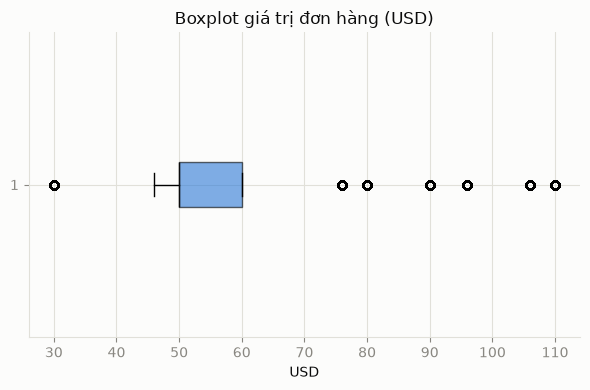

items_purchased  price_usd
1                29.99         534
2                75.98         662
                 79.98        3142
                 89.98         680
                 95.98        2036
                 105.98        248
                 109.98        944
dtype: int64

In [9]:
order_val = orders['price_usd']
q1, q3 = order_val.quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = order_val[(order_val < low) | (order_val > high)]
print(f'IQR bounds: [{low:.2f}, {high:.2f}] USD | Outliers: {len(outliers)} ({len(outliers)/len(order_val)*100:.1f}%)')

fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot(order_val, orientation='horizontal', patch_artist=True,
           boxprops=dict(facecolor=PALETTE[0], alpha=0.6), medianprops=dict(color=INK))
ax.set_title('Boxplot giá trị đơn hàng (USD)')
ax.set_xlabel('USD')
plt.tight_layout()
plt.show()

display(orders.loc[outliers.index].groupby(['items_purchased', 'price_usd']).size())

**Nhận xét:** theo IQR có tới **25.5% đơn là outlier**, nhưng bảng trên cho thấy:
- **7,712 đơn** là đơn có **2 sản phẩm**, giá 75.98–109.98 USD, cao hơn cận trên.
- **534 đơn** là đơn 1 sản phẩm, đều có giá **29.99 USD** (mức giá thấp nhất), thấp hơn cận dưới.

Giá trị đơn chỉ nhận vài mức cố định, nên IQR không phù hợp. Đây là **giá trị thật**, không phải lỗi → **không loại bỏ**.

→ Sau bước làm sạch, dữ liệu **không có dòng nào bị loại** (không có NA, không trùng, outlier đều là giá trị thật).

## 5. Feature Engineering

### 5.1. Bảng chi tiết sản phẩm `item_df`
Bảng `orders` chỉ ghi tổng tiền của cả đơn, nên không biết tiền đó thuộc sản phẩm nào khi một đơn mua 2 món. Vì vậy, để tính doanh thu theo từng sản phẩm, notebook dùng bảng `order_items` (mỗi dòng là 1 món trong đơn), rồi ghép thêm tên sản phẩm và tính lợi nhuận gộp.

In [10]:
item_df = items.merge(products[['product_id', 'product_name']], on='product_id', how='left')
item_df['gross_profit'] = item_df['price_usd'] - item_df['cogs_usd']

print('Số dòng order_items:', len(items), '| Số dòng sau merge:', len(item_df))
item_df.head()

Số dòng order_items: 40025 | Số dòng sau merge: 40025


,order_item_id,created_at,order_id,product_id,is_primary_item,price_usd,cogs_usd,product_name,gross_profit
0,1,2012-03-19 10:42:46,1,1,1,49.99,19.49,The Original Mr. Fuzzy,30.50
1,2,2012-03-19 19:27:37,2,1,1,49.99,19.49,The Original Mr. Fuzzy,30.50
2,3,2012-03-20 06:44:45,3,1,1,49.99,19.49,The Original Mr. Fuzzy,30.50
3,4,2012-03-20 09:41:45,4,1,1,49.99,19.49,The Original Mr. Fuzzy,30.50
4,5,2012-03-20 11:28:15,5,1,1,49.99,19.49,The Original Mr. Fuzzy,30.50


### 5.2. Tách năm / tháng từ created_at

In [11]:
for t in (orders, item_df):
    t['year'] = t['created_at'].dt.year
    t['month'] = t['created_at'].dt.month
    t['year_month'] = t['created_at'].dt.to_period('M')

orders[['created_at', 'year', 'month', 'year_month']].head()

,created_at,year,month,year_month
0,2012-03-19 10:42:46,2012,3,2012-03
1,2012-03-19 19:27:37,2012,3,2012-03
2,2012-03-20 06:44:45,2012,3,2012-03
3,2012-03-20 09:41:45,2012,3,2012-03
4,2012-03-20 11:28:15,2012,3,2012-03


## 6. Exploratory Data Analysis (EDA) & Pareto

### 6.1. Tổng hợp các chỉ số cơ bản (KPI)

In [12]:
kpi = pd.Series({
    'Số đơn hàng': orders['order_id'].nunique(),
    'Số khách hàng': orders['user_id'].nunique(),
    'Số sản phẩm bán ra': len(item_df),
    'Doanh thu (USD)': item_df['price_usd'].sum(),
    'Lợi nhuận gộp (USD)': item_df['gross_profit'].sum(),
    'Biên lợi nhuận gộp (%)': item_df['gross_profit'].sum() / item_df['price_usd'].sum() * 100,
    'AOV - giá trị đơn TB (USD)': orders['price_usd'].mean(),
    'Tỷ lệ đơn có bán kèm (%)': (orders['items_purchased'] > 1).mean() * 100,
})
kpi.to_frame('value')

,value
Số đơn hàng,32313.00
Số khách hàng,31696.00
Số sản phẩm bán ra,40025.00
Doanh thu (USD),1938509.75
Lợi nhuận gộp (USD),1216139.50
Biên lợi nhuận gộp (%),62.74
AOV - giá trị đơn TB (USD),59.99
Tỷ lệ đơn có bán kèm (%),23.87


**Nhận xét:** trong 3 năm, cửa hàng có **32,313 đơn** từ **31,696 khách hàng**, doanh thu **1.94 triệu USD**, lợi nhuận gộp **1.22 triệu USD** (biên 62.7%).
- AOV là **59.99 USD**. Khoảng **23.9%** đơn có mua thêm sản phẩm thứ 2.

#### KPI theo năm

In [13]:
kpi_year = (orders.groupby('year')
                  .agg(orders=('order_id', 'nunique'),
                       customers=('user_id', 'nunique'),
                       aov_usd=('price_usd', 'mean'),
                       cross_sell_pct=('items_purchased', lambda s: (s > 1).mean() * 100),
                       months=('year_month', 'nunique'))
                  .join(item_df.groupby('year').agg(revenue=('price_usd', 'sum'),
                                                    gross_profit=('gross_profit', 'sum'))))
kpi_year['gross_margin_pct'] = kpi_year['gross_profit'] / kpi_year['revenue'] * 100
kpi_year['revenue_per_month'] = kpi_year['revenue'] / kpi_year['months']
kpi_year

,orders,customers,aov_usd,cross_sell_pct,months,revenue,gross_profit,gross_margin_pct,revenue_per_month
year,,,,,,,,,
2012,2586,2569,49.99,0.00,10,129274.14,78873.00,61.01,12927.41
2013,7447,7343,52.81,2.23,12,393247.87,241596.50,61.44,32770.66
2014,16860,16547,63.80,33.93,12,1075612.19,679722.50,63.19,89634.35
2015,5420,5327,62.80,33.67,3,340375.55,215947.50,63.44,113458.52


**Nhận xét KPI theo năm:**
- **AOV tăng từ 49.99 USD (2012) lên ~63 USD (2014–2015)**, nhờ tỷ lệ đơn có bán kèm tăng từ 0% lên ~34%.
- **Biên lợi nhuận gộp tăng dần** từ 61.0% lên 63.4%, khi các sản phẩm mới có biên cao hơn được bán nhiều hơn.
- **Doanh thu trung bình mỗi tháng** tăng từ ~12.9 nghìn USD (2012) lên ~113.5 nghìn USD (2015).
- Cột `months` cho thấy năm 2012 chỉ có 10 tháng và năm 2015 chỉ có 3 tháng dữ liệu, nên so sánh bằng doanh thu trung bình mỗi tháng (`revenue_per_month`), không so tổng.

### 6.2. Doanh thu theo tháng

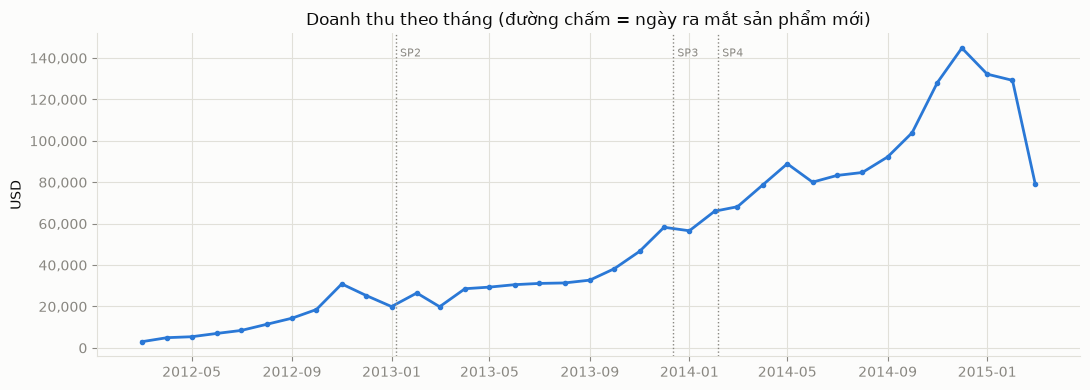

Doanh thu theo năm:
year
2012      129,274
2013      393,248
2014    1,075,612
2015      340,376


In [14]:
monthly = item_df.groupby('year_month')['price_usd'].sum()
monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(monthly.index, monthly.values, color=PALETTE[0], marker='o', markersize=3, linewidth=2)
for _, row in products.iloc[1:].iterrows():  # đánh dấu ngày ra mắt sản phẩm 2, 3, 4
    ax.axvline(row['created_at'], color=MUTED, linestyle=':', linewidth=1)
    ax.text(row['created_at'], monthly.max(), f" SP{row['product_id']}", color=MUTED, fontsize=8, va='top')
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
ax.set_title('Doanh thu theo tháng (đường chấm = ngày ra mắt sản phẩm mới)')
ax.set_ylabel('USD')
plt.tight_layout()
plt.show()

print('Doanh thu theo năm:'); print(item_df.groupby('year')['price_usd'].sum().map('{:,.0f}'.format).to_string())

**Nhận xét:** doanh thu tăng trưởng liên tục: từ ~3 nghìn USD (03/2012) lên đỉnh **144,823 USD vào 12/2014**. Doanh thu năm 2014 (1.08 triệu USD) gấp **2.7 lần** năm 2013 (cả 2 năm đều đủ 12 tháng).
- Doanh thu tăng nhanh từ khoảng 09/2013, trước cả khi ra mắt sản phẩm 3 và 4. Sau khi có đủ 4 sản phẩm, doanh thu tiếp tục tăng. Biểu đồ chỉ cho thấy các sự kiện xảy ra cùng thời điểm, chưa đủ bằng chứng để kết luận sản phẩm là nguyên nhân tăng trưởng, biểu đồ phản ánh xu hướng là chính.
- Doanh thu cao nhất vào cuối năm (11–12/2012, 11–12/2014), phù hợp với mùa mua sắm lễ.
- Tháng 03/2015 giảm mạnh **chỉ vì dữ liệu dừng ở ngày 19/03**, không phản ánh xu hướng thật.

### 6.3. Pareto: sản phẩm nào tạo ra 80% doanh thu và lợi nhuận gộp?

In [15]:
def pareto_table(data, dim, value, agg='sum'):       #tạo ra công thức mẫu cho bảng Pareto
    t = (data.groupby(dim, as_index=False)
             .agg(total=(value, agg))
             .sort_values('total', ascending=False)
             .reset_index(drop=True))
    t['pct'] = t['total'] * 100 / t['total'].sum()
    t['cum_pct'] = t['pct'].cumsum()
    t['group'] = np.where(t['cum_pct'] - t['pct'] < 80, 'Nhóm chính (80%)', 'Nhóm còn lại')
    return t


def plot_pareto(t, dim, title, ylabel, ax=None):
    #cột = giá trị, đường = % lũy kế, ngưỡng 80%
    if ax is None:
        _, ax = plt.subplots(figsize=(9, 5))
    colors = np.where(t['group'] == 'Nhóm chính (80%)', PALETTE[1], '#A9A9A9')
    bars = ax.bar(t[dim].astype(str), t['total'], color=colors, edgecolor=INK, linewidth=0.5)
    ax.bar_label(bars, labels=[f'{p:.1f}%' for p in t['pct']], fontsize=8, padding=2)
    ax.set_ylabel(ylabel, fontweight='bold')
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
    ax.grid(axis='x', visible=False)
    plt.setp(ax.get_xticklabels(), rotation=20, ha='right', rotation_mode='anchor')

    ax2 = ax.twinx()
    ax2.plot(t[dim].astype(str), t['cum_pct'], color=PALETTE[0], marker='o', linewidth=2, label='Tích lũy (%)')
    ax2.axhline(80, color=PALETTE[7], linestyle='--', linewidth=1.5, label='Ngưỡng 80%')
    ax2.set_ylim(0, 105)
    ax2.set_ylabel('Tỷ lệ tích lũy (%)', color=PALETTE[0], fontweight='bold')
    ax2.grid(False)
    ax2.spines['right'].set_visible(True)

    handles = [Patch(facecolor=PALETTE[1], label='Nhóm tạo 80%'),
               Patch(facecolor='#A9A9A9', label='Nhóm còn lại')] + ax2.get_legend_handles_labels()[0]
    ax2.legend(handles=handles, loc='center right', fontsize=8)
    ax.set_title(title, fontweight='bold')
    return ax

Bảng 1: Pareto doanh thu theo sản phẩm


,product_name,total,pct,cum_pct,group
0,The Original Mr. Fuzzy,1211057.74,62.47,62.47,Nhóm chính (80%)
1,The Forever Love Bear,347702.04,17.94,80.41,Nhóm chính (80%)
2,The Birthday Sugar Panda,229260.15,11.83,92.24,Nhóm còn lại
3,The Hudson River Mini bear,150489.82,7.76,100.00,Nhóm còn lại


Bảng 2: Pareto lợi nhuận gộp theo sản phẩm (kèm biên lợi nhuận gộp)


,product_name,total,pct,cum_pct,group,gross_margin_pct
0,The Original Mr. Fuzzy,738893.00,60.76,60.76,Nhóm chính (80%),61.01
1,The Forever Love Bear,217350.00,17.87,78.63,Nhóm chính (80%),62.51
2,The Birthday Sugar Panda,157027.50,12.91,91.54,Nhóm chính (80%),68.49
3,The Hudson River Mini bear,102869.00,8.46,100.00,Nhóm còn lại,68.36


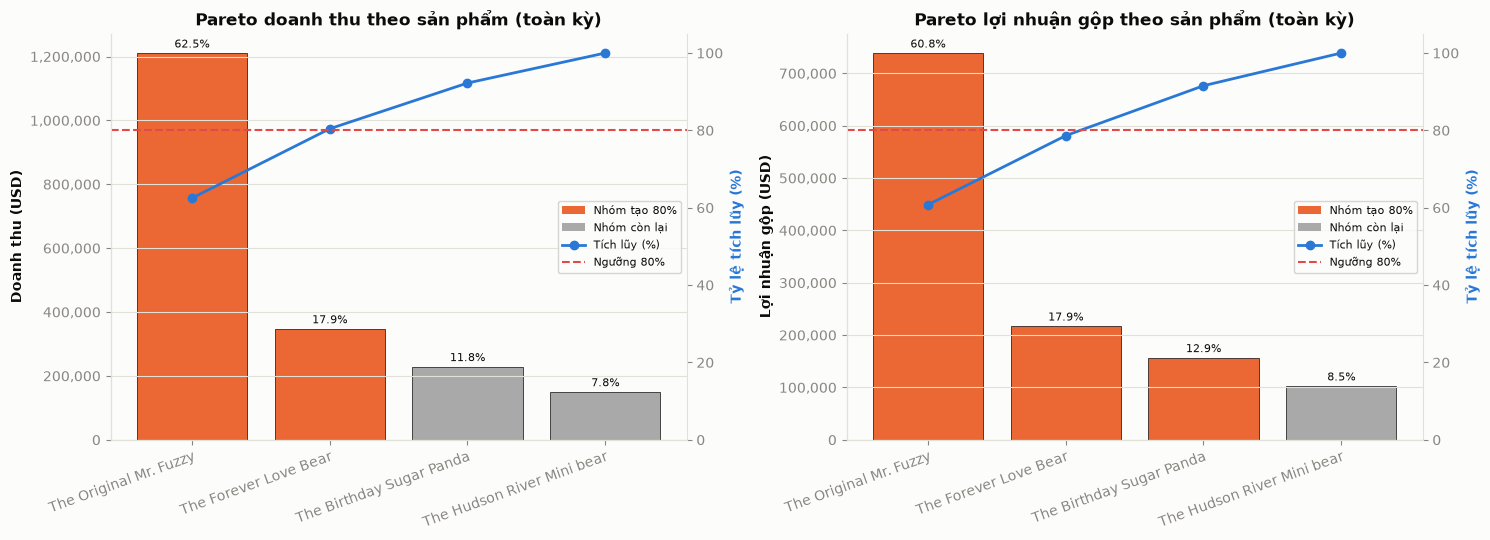

In [ ]:
pareto_rev = pareto_table(item_df, 'product_name', 'price_usd') #pareto_table(data, dim, value)
pareto_gp = pareto_table(item_df, 'product_name', 'gross_profit')

# Biên lợi nhuận gộp của từng sản phẩm dành cho Pareto lợi nhuận gộp.
margin = (pareto_gp.set_index('product_name')['total'] / pareto_rev.set_index('product_name')['total'] * 100).rename('gross_margin_pct') #= lợi nhuận gộp / doanh thu * 100, đặt tên cột là gross_margin_pct
print('Bảng 1: Pareto doanh thu theo sản phẩm'); display(pareto_rev)
print('Bảng 2: Pareto lợi nhuận gộp theo sản phẩm (kèm biên lợi nhuận gộp)'); display(pareto_gp.merge(margin, left_on='product_name', right_index=True))
#display bảng pareto_gp, merge với bảng margin thông qua product_name để có thêm cột biên lợi nhuận gộp.

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
plot_pareto(pareto_rev, 'product_name', 'Pareto doanh thu theo sản phẩm (toàn kỳ)', 'Doanh thu (USD)', axes[0])
plot_pareto(pareto_gp, 'product_name', 'Pareto lợi nhuận gộp theo sản phẩm (toàn kỳ)', 'Lợi nhuận gộp (USD)', axes[1])
plt.tight_layout()
plt.show()

**Nhận xét:**
- **Doanh thu:** chỉ riêng **The Original Mr. Fuzzy đã chiếm 62.5%**. Cộng thêm The Forever Love Bear là vượt ngưỡng 80% (80.4%). → **2/4 sản phẩm (50%) tạo ra 80% doanh thu**. Tỷ lệ này không phải 20/80 kinh điển (danh mục chỉ có 4 sản phẩm), nhưng doanh thu vẫn tập trung mạnh vào 1 sản phẩm.
- **Lợi nhuận gộp:** Mr. Fuzzy chiếm 60.8%, thấp hơn tỷ trọng doanh thu, vì biên lợi nhuận của nó thấp nhất (61.0%, so với ~68% của Sugar Panda và Mini bear). 2 sản phẩm đầu chỉ đạt 78.6% → **cần 3 sản phẩm** mới vượt 80% lợi nhuận.

Tuy nhiên, Mr. Fuzzy được bán từ 2012, còn các sản phẩm khác ra mắt muộn hơn 10–23 tháng, nên kết quả này bị thiên lệch do **thời gian bán khác nhau** 

#### So sánh công bằng: chỉ xét giai đoạn đủ 4 sản phẩm

4 sản phẩm ra mắt ở 4 thời điểm khác nhau, nên sản phẩm 1 có lợi thế về **thời gian bán**. Để so sánh công bằng, lặp lại Pareto chỉ trong giai đoạn từ ngày ra mắt sản phẩm cuối cùng đến hết dữ liệu.

Giai đoạn so sánh: 2014-02-05 -> 2015-03-19 (406 ngày, 28,561 item)
Bảng 3: Pareto doanh thu – giai đoạn đủ 4 sản phẩm


,product_name,total,pct,cum_pct,group
0,The Original Mr. Fuzzy,733503.27,54.27,54.27,Nhóm chính (80%)
1,The Forever Love Bear,255377.43,18.90,73.17,Nhóm chính (80%)
2,The Birthday Sugar Panda,212151.87,15.70,88.87,Nhóm chính (80%)
3,The Hudson River Mini bear,150489.82,11.13,100.00,Nhóm còn lại


Bảng 4: Pareto lợi nhuận gộp – giai đoạn đủ 4 sản phẩm (kèm biên lợi nhuận gộp)


,product_name,total,pct,cum_pct,group,gross_margin_pct
0,The Original Mr. Fuzzy,447526.50,52.32,52.32,Nhóm chính (80%),61.01
1,The Forever Love Bear,159637.50,18.66,70.98,Nhóm chính (80%),62.51
2,The Birthday Sugar Panda,145309.50,16.99,87.97,Nhóm chính (80%),68.49
3,The Hudson River Mini bear,102869.00,12.03,100.00,Nhóm còn lại,68.36


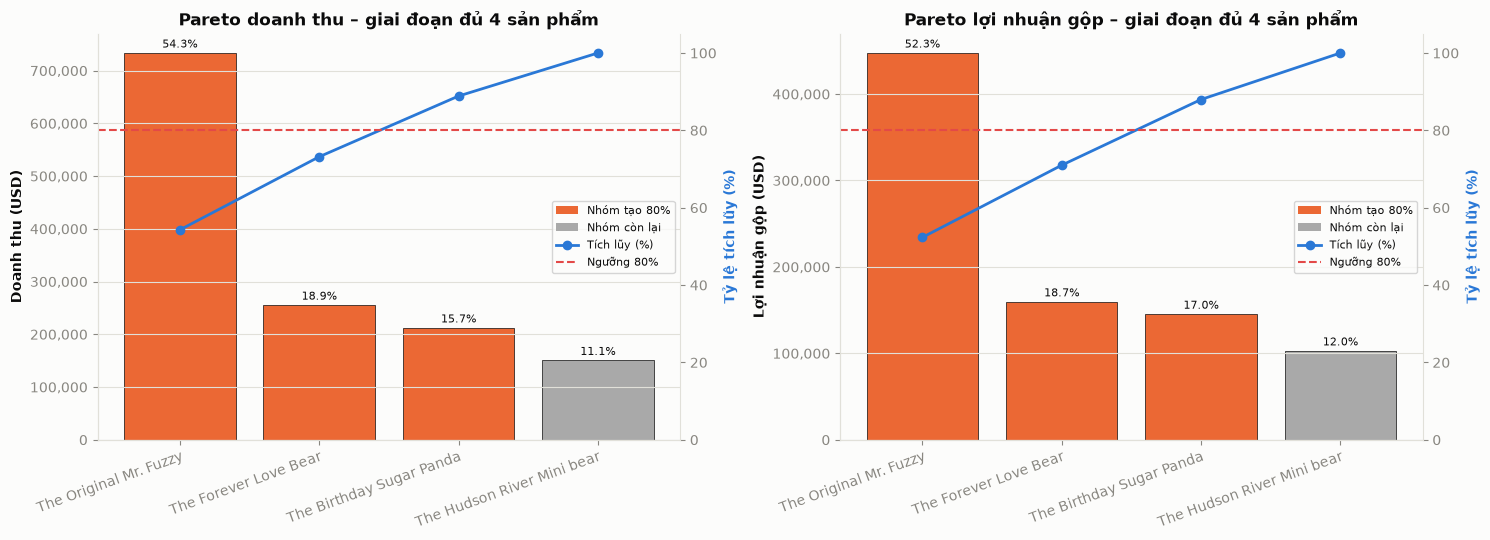

In [18]:
start_all = products['created_at'].max()
item_recent = item_df[item_df['created_at'] >= start_all]
print(f'Giai đoạn so sánh: {start_all.date()} -> {item_df["created_at"].max().date()} '
      f'({(item_df["created_at"].max() - start_all).days} ngày, {len(item_recent):,} item)')

pareto_rev_recent = pareto_table(item_recent, 'product_name', 'price_usd')
pareto_gp_recent = pareto_table(item_recent, 'product_name', 'gross_profit')

print('Bảng 3: Pareto doanh thu – giai đoạn đủ 4 sản phẩm'); display(pareto_rev_recent)
print('Bảng 4: Pareto lợi nhuận gộp – giai đoạn đủ 4 sản phẩm (kèm biên lợi nhuận gộp)'); display(pareto_gp_recent.merge(margin, left_on='product_name', right_index=True))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
plot_pareto(pareto_rev_recent, 'product_name', 'Pareto doanh thu – giai đoạn đủ 4 sản phẩm', 'Doanh thu (USD)', axes[0])
plot_pareto(pareto_gp_recent, 'product_name', 'Pareto lợi nhuận gộp – giai đoạn đủ 4 sản phẩm', 'Lợi nhuận gộp (USD)', axes[1])
plt.tight_layout()
plt.show()

**Nhận xét:** trong giai đoạn cả 4 sản phẩm cùng được bán (05/02/2014 – 19/03/2015):
- Tỷ trọng doanh thu của Mr. Fuzzy giảm từ 62.5% xuống **54.3%**. Lúc này **cần 3 sản phẩm** mới đạt 80% doanh thu (88.9%), và cũng 3 sản phẩm cho lợi nhuận gộp.
- → Mức độ tập trung ở mục trên một phần là do Mr. Fuzzy được bán lâu hơn. Khi so sánh công bằng, danh mục đang phân tán dần: các sản phẩm mới đã đóng góp gần một nửa doanh thu.
- Sugar Panda và Mini bear có biên lợi nhuận cao nhất (~68.5%), nên tỷ trọng lợi nhuận của 2 sản phẩm này cao hơn tỷ trọng doanh thu. Ngược lại, Mr. Fuzzy chiếm 54.3% doanh thu nhưng chỉ 52.3% lợi nhuận.

Mr. Fuzzy vẫn là sản phẩm quan trọng nhất (> 50% doanh thu và lợi nhuận), nhưng không còn chiếm tỉ trọng quá lớn như số liệu toàn kỳ cho thấy.

## 7. Kết luận & Đề xuất

### 7.1. Phát hiện chính
- **Doanh thu tập trung vào 1 sản phẩm, nhưng đang phân tán dần.** Toàn kỳ, The Original Mr. Fuzzy chiếm 62.5% doanh thu và 2/4 sản phẩm tạo ra 80% doanh thu. Khi so sánh trong cùng giai đoạn đủ 4 sản phẩm, tỷ trọng của Mr. Fuzzy giảm còn 54.3% và cần 3 sản phẩm mới đạt 80%.
- **Lợi nhuận gộp phân tán hơn doanh thu.** Mr. Fuzzy có biên lợi nhuận gộp thấp nhất (61.0%), còn Sugar Panda và Mini bear ~68.5% → các sản phẩm mới đóng góp lợi nhuận gộp nhiều hơn tỷ trọng doanh thu của chúng.
- **Doanh thu tăng trưởng mạnh:** năm 2014 gấp 2.7 lần năm 2013.

### 7.2. Đề xuất
- **Bảo vệ sản phẩm chủ lực Mr. Fuzzy:** đây vẫn là sản phẩm chiếm > 50% doanh thu và lợi nhuận gộp, nên mọi vấn đề về nguồn hàng hay chất lượng của sản phẩm này ảnh hưởng lớn nhất đến cửa hàng.
- **Tiếp tục phát triển các sản phẩm biên lợi nhuận cao:** Sugar Panda và Mini bear có biên ~68.5%. Mở rộng danh mục giúp giảm phụ thuộc vào Mr. Fuzzy và tăng biên lợi nhuận gộp chung.
- **Xem xét lại giá vốn hoặc giá bán của Mr. Fuzzy:** sản phẩm bán nhiều nhất lại có biên thấp nhất, nên chỉ cần cải thiện biên một chút cũng tác động lớn đến tổng lợi nhuận gộp.